# Chapter 7 — Unsupervised Learning

**Book:** Practical Statistics for Data Scientists, 2nd Edition

**Name:** Rainaldi Pakpahan
**NIM:** 101032300084
**Class:** TK 47-04

**Name:** Firdaus Arif Ramadhani
**NIM:** 101032300131
**Class:** TK 47-04

## Tujuan

Chapter ini membahas unsupervised learning, yaitu metode untuk
menemukan struktur pada data tanpa variabel target.

Pembahasan meliputi Principal Components Analysis (PCA) untuk
mereduksi dimensi, correspondence analysis untuk data kategorikal,
serta clustering dengan K-means, hierarchical clustering, dan
model-based clustering. Bagian akhir membahas pengaruh penskalaan
variabel dan data kategorikal pada hasil analisis.

## Alur Pembahasan

1. Menyiapkan dataset
2. Principal Components Analysis (PCA)
3. Correspondence Analysis
4. K-Means Clustering
5. Hierarchical Clustering
6. Model-Based Clustering
7. Penskalaan Variabel dan Data Kategorikal
8. Ringkasan
9. Kesimpulan

In [1]:
from pathlib import Path
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform
from scipy.stats import multivariate_normal

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)

print("Library berhasil dimuat.")

Library berhasil dimuat.


### Interpretasi

Library berhasil dimuat dan siap digunakan untuk PCA, clustering,
serta visualisasi hasilnya.

## 1. Menyiapkan Dataset

Chapter ini memakai empat dataset dari repository resmi buku:

- `sp500_data.csv.gz`: perubahan harga penutupan harian 517 saham S&P 500 dari 29 Januari 1993 sampai 1 Juli 2015. Dipakai untuk PCA, K-means, hierarchical clustering, dan model-based clustering.
- `sp500_sectors.csv`: sektor setiap saham. Dipakai untuk membaca hasil PCA.
- `loan_data.csv.gz`: data pinjaman Lending Club. Dipakai untuk contoh penskalaan variabel dan data kategorikal.
- `housetasks.csv`: jumlah rumah tangga untuk setiap tugas rumah tangga menurut pelaksananya. Dipakai untuk correspondence analysis.

In [2]:
REPO_DIR = Path("/content/practical-statistics-for-data-scientists")
REPO_URL = "https://github.com/gedeck/practical-statistics-for-data-scientists.git"

if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)],
        check=True
    )

DATA_DIR = REPO_DIR / "data"

print("Lokasi dataset:")
print(DATA_DIR)

Lokasi dataset:
/content/practical-statistics-for-data-scientists/data


In [3]:
sp500_px = pd.read_csv(DATA_DIR / "sp500_data.csv.gz", index_col=0)
sp500_sectors = pd.read_csv(DATA_DIR / "sp500_sectors.csv")
loan_data = pd.read_csv(DATA_DIR / "loan_data.csv.gz")
housetasks = pd.read_csv(DATA_DIR / "housetasks.csv", index_col=0)

print("sp500_data :", sp500_px.shape, "|", sp500_px.index[0], "sampai", sp500_px.index[-1])
print("Missing value pada sp500_data :", int(sp500_px.isna().sum().sum()))
print("loan_data  :", loan_data.shape)
print("housetasks :", housetasks.shape)

housetasks

sp500_data : (5647, 517) | 1993-01-29 sampai 2015-07-01
Missing value pada sp500_data : 0
loan_data  : (45342, 21)
housetasks : (13, 4)


,Wife,Alternating,Husband,Jointly
Task,,,,
Laundry,156,14,2,4
Main_meal,124,20,5,4
Dinner,77,11,7,13
Breakfast,82,36,15,7
Tidying,53,11,1,57
Dishes,32,24,4,53
Shopping,33,23,9,55
Official,12,46,23,15
Driving,10,51,75,3


### Interpretasi

Data harga berisi 5,647 hari perdagangan dan 517 saham tanpa missing
value. Nilainya adalah perubahan harga harian, sehingga positif ketika
harga naik dan negatif ketika harga turun. `loan_data` berisi 45,342
pinjaman dengan 21 kolom.

Tabel `housetasks` berisi 13 tugas rumah tangga yang dihitung menurut
pelaksananya. Misalnya, Laundry dikerjakan istri pada 156 rumah tangga,
Repairs dikerjakan suami pada 160 rumah tangga, dan Holidays dikerjakan
bersama pada 153 rumah tangga.

## 2. Principal Components Analysis (PCA)

PCA mencari kombinasi linear dari variabel-variabel asli, yang disebut principal component, yang menjelaskan variasi data sebanyak mungkin. Component pertama (PC1) adalah arah dengan variance terbesar, component kedua (PC2) adalah arah dengan variance terbesar berikutnya yang tegak lurus dengan PC1, dan seterusnya. Bobot setiap variabel pada sebuah component disebut loading.

PCA bekerja pada data yang sudah dipusatkan (dikurangi rata-rata) dan menghitung variance pada skala asli variabel, sehingga variabel dengan variance besar dapat mendominasi hasilnya. Hal ini dibahas pada bagian 7.

Tanda sebuah component bersifat sembarang: PC1 dan -PC1 menyatakan arah yang sama. Agar hasilnya konsisten, tanda setiap component pada notebook ini dibalik sehingga loading dengan nilai mutlak terbesar bernilai positif.

In [4]:
def orient_components(components):
    """Balik tanda setiap component agar loading dengan nilai mutlak terbesar bernilai positif."""
    largest = np.abs(components).argmax(axis=1)
    signs = np.sign(components[np.arange(len(components)), largest])
    return components * signs[:, None]

### Contoh Sederhana: XOM dan CVX

Contoh pertama memakai dua saham perusahaan minyak, ExxonMobil (XOM) dan Chevron (CVX), yang harganya bergerak searah. Dua variabel yang berkorelasi dapat diringkas oleh satu component.

In [5]:
oil_px = sp500_px[["XOM", "CVX"]]

pca_oil = PCA(n_components=2)
pca_oil.fit(oil_px)

loadings_oil = pd.DataFrame(
    orient_components(pca_oil.components_),
    columns=oil_px.columns,
    index=["PC1", "PC2"]
)

variance_oil = pd.DataFrame(
    {
        "Variance": pca_oil.explained_variance_,
        "Proporsi": pca_oil.explained_variance_ratio_,
    },
    index=["PC1", "PC2"]
)

print(f"Korelasi XOM dan CVX: {oil_px['XOM'].corr(oil_px['CVX']):.3f}")
print("\nLoadings:")
print(loadings_oil)
print("\nVariance yang dijelaskan:")
print(variance_oil)

Korelasi XOM dan CVX: 0.790

Loadings:
      XOM    CVX
PC1 0.665  0.747
PC2 0.747 -0.665

Variance yang dijelaskan:
     Variance  Proporsi
PC1     0.778     0.896
PC2     0.090     0.104


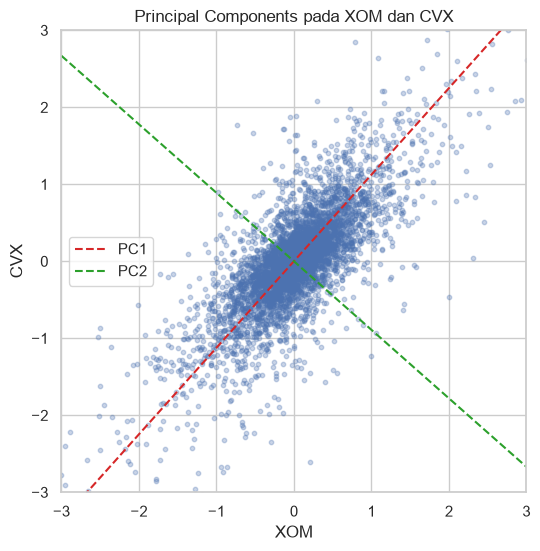

In [6]:
fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(oil_px["XOM"], oil_px["CVX"], alpha=0.3, s=10)

x_values = np.array([-3, 3])

for name, color in [("PC1", "tab:red"), ("PC2", "tab:green")]:
    slope = loadings_oil.loc[name, "CVX"] / loadings_oil.loc[name, "XOM"]
    ax.plot(x_values, slope * x_values, "--", color=color, label=name)

ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.set_xlabel("XOM")
ax.set_ylabel("CVX")
ax.set_title("Principal Components pada XOM dan CVX")
ax.legend()

plt.show()

### Interpretasi

XOM dan CVX berkorelasi tinggi (0.790): ketika harga satu saham naik,
harga saham lainnya cenderung naik juga. Karena itu hampir seluruh
variasi data dapat diringkas oleh satu component. PC1 menjelaskan 89.6%
dari total variance (0.778 dari 0.869), sedangkan PC2 hanya 10.4%
(0.090). Loading PC1 positif untuk kedua saham (0.665 untuk XOM dan
0.747 untuk CVX), sehingga PC1 mewakili gerakan bersama kedua saham yang
searah.

Loading PC2 (0.747 dan -0.665) memiliki tanda berlawanan, sehingga PC2
menangkap perbedaan gerakan antara XOM dan CVX, yaitu hari-hari ketika
satu saham naik dan yang lain turun. Pada gambar, garis merah (PC1)
mengikuti arah memanjang awan titik dan garis hijau (PC2) tegak lurus
dengannya, ke arah dengan sebaran yang paling sempit.

### Menafsirkan Principal Components

Contoh kedua memakai 16 saham dari empat kelompok: teknologi, energi, keuangan, dan ritel, sejak 1 Januari 2011. Scree plot memperlihatkan variance setiap component sehingga jumlah component yang perlu dipertahankan dapat ditentukan, sedangkan loading memperlihatkan makna setiap component.

In [7]:
sector_of = sp500_sectors.set_index("symbol")["sector"]

symbols = sorted([
    "AAPL", "MSFT", "CSCO", "INTC", "CVX", "XOM", "SLB", "COP",
    "JPM", "WFC", "USB", "AXP", "WMT", "TGT", "HD", "COST"
])

top_sp = sp500_px.loc[sp500_px.index >= "2011-01-01", symbols]

sp_pca = PCA()
sp_pca.fit(top_sp)

components = [f"PC{i}" for i in range(1, 11)]

variance = pd.DataFrame(
    {
        "Variance": sp_pca.explained_variance_[:10],
        "Proporsi": sp_pca.explained_variance_ratio_[:10],
        "Kumulatif": np.cumsum(sp_pca.explained_variance_ratio_)[:10],
    },
    index=components
)

print(f"Data: {top_sp.shape[0]} hari x {top_sp.shape[1]} saham (sejak 2011-01-01)")
print("\nJumlah saham per sektor:")
print(sector_of[symbols].value_counts().to_string())
print()
print(variance)

Data: 1131 hari x 16 saham (sejak 2011-01-01)

Jumlah saham per sektor:
sector
information_technology    4
financials                4
energy                    4
consumer_staples          2
consumer_discretionary    2

      Variance  Proporsi  Kumulatif
PC1      3.215     0.445      0.445
PC2      1.037     0.143      0.588
PC3      0.759     0.105      0.693
PC4      0.449     0.062      0.755
PC5      0.384     0.053      0.809
PC6      0.301     0.042      0.850
PC7      0.205     0.028      0.879
PC8      0.175     0.024      0.903
PC9      0.152     0.021      0.924
PC10     0.151     0.021      0.945


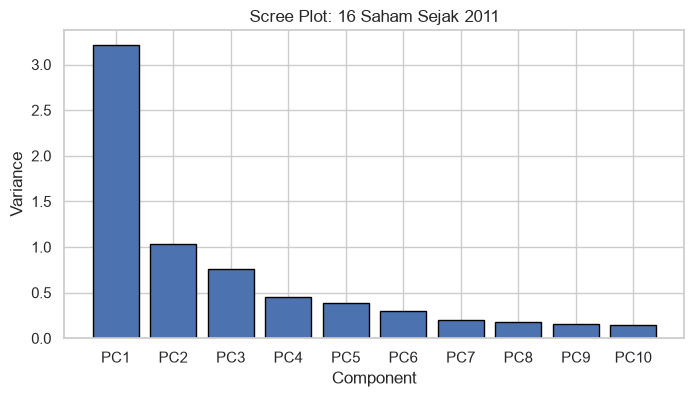

In [8]:
plt.figure(figsize=(8, 4))

plt.bar(variance.index, variance["Variance"], edgecolor="black")

plt.xlabel("Component")
plt.ylabel("Variance")
plt.title("Scree Plot: 16 Saham Sejak 2011")

plt.show()

### Interpretasi

Variance turun tajam dari PC1 (3.215) ke PC2 (1.037), lalu turun
perlahan. PC1 saja menjelaskan 44.5% variance dari 16 saham, dua
component pertama 58.8%, dan lima component pertama 80.9%. Sepuluh
component menjelaskan 94.5%, sehingga 16 variabel asli dapat diringkas
menjadi sekitar 5 sampai 10 component dengan kehilangan informasi yang
kecil.

Penurunan terbesar terjadi dari PC1 ke PC2, sedangkan component
sesudahnya masing-masing hanya menambah sedikit. Jumlah component yang
dipertahankan ditentukan dari kebutuhan analisis: lebih sedikit
component lebih mudah ditafsirkan, lebih banyak component menyimpan
lebih banyak informasi.

In [9]:
loadings = pd.DataFrame(
    orient_components(sp_pca.components_[:5]),
    columns=top_sp.columns,
    index=components[:5]
)

sector_loadings = loadings.transpose().groupby(sector_of[symbols]).mean()

print("Loading setiap saham:")
print(loadings.transpose())

print("\nRata-rata loading per sektor:")
print(sector_loadings)

Loading setiap saham:
       PC1    PC2    PC3    PC4    PC5
AAPL 0.301  0.505  0.787 -0.121 -0.112
AXP  0.246  0.139 -0.135  0.062  0.597
COP  0.262 -0.174  0.002 -0.206  0.006
COST 0.274  0.416 -0.466  0.093 -0.556
CSCO 0.064  0.032  0.008  0.004  0.040
CVX  0.444 -0.289 -0.082 -0.578 -0.109
HD   0.208  0.278 -0.166  0.163  0.185
INTC 0.077  0.034  0.004 -0.002  0.072
JPM  0.196  0.041 -0.062  0.058  0.385
MSFT 0.105  0.054 -0.016 -0.013  0.077
SLB  0.482 -0.472  0.195  0.681 -0.181
TGT  0.149  0.228 -0.161  0.110  0.056
USB  0.116  0.055 -0.049  0.017  0.155
WFC  0.146  0.047 -0.042  0.019  0.216
WMT  0.122  0.223 -0.176  0.058 -0.092
XOM  0.318 -0.154 -0.090 -0.295 -0.013

Rata-rata loading per sektor:
                         PC1    PC2    PC3    PC4    PC5
sector                                                  
consumer_discretionary 0.178  0.253 -0.164  0.136  0.121
consumer_staples       0.198  0.320 -0.321  0.076 -0.324
energy                 0.376 -0.273  0.006 -0.099 -0.074

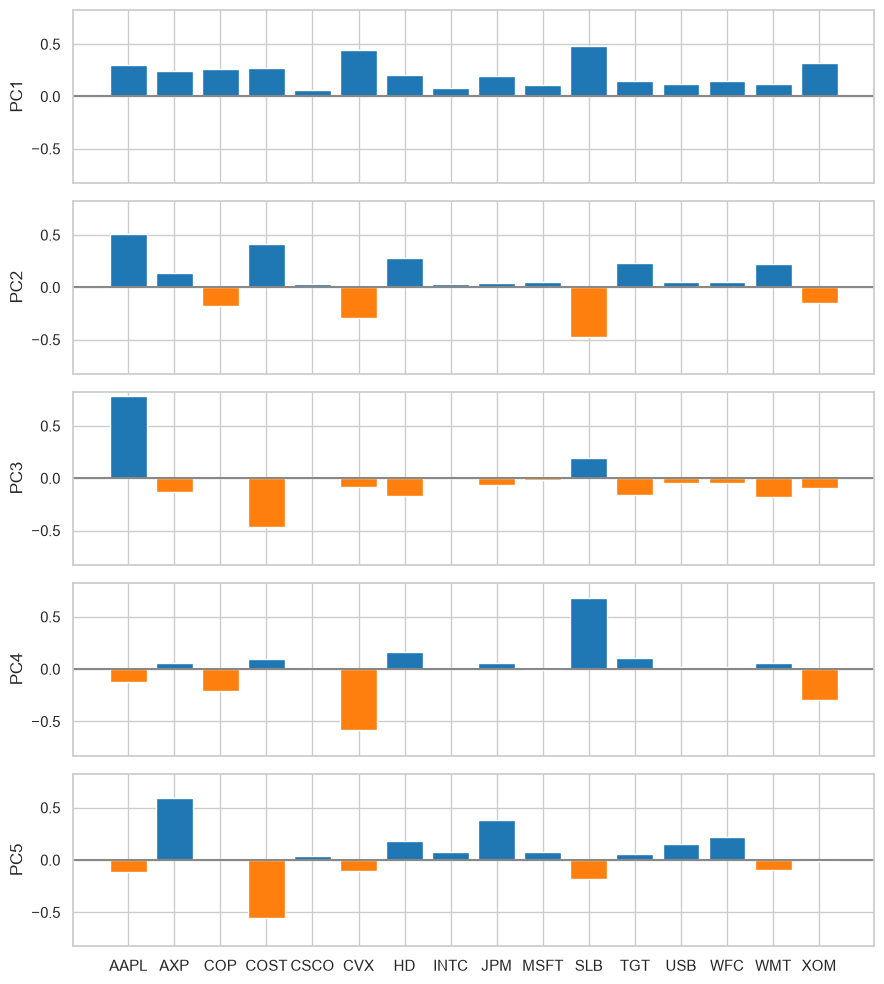

In [10]:
limit = 1.05 * loadings.abs().to_numpy().max()

fig, axes = plt.subplots(5, 1, figsize=(9, 10), sharex=True)

for ax, (name, row) in zip(axes, loadings.iterrows()):
    colors = ["tab:blue" if value > 0 else "tab:orange" for value in row]

    ax.axhline(0, color="#888888")
    ax.bar(row.index, row.values, color=colors)
    ax.set_ylabel(name)
    ax.set_ylim(-limit, limit)

plt.tight_layout()
plt.show()

### Interpretasi

PC1 memiliki loading positif pada seluruh saham (0.064 sampai 0.482),
sehingga PC1 mewakili gerakan pasar secara keseluruhan: ketika PC1
tinggi, hampir semua saham naik. Loading terbesar berada pada saham
energi, yaitu SLB (0.482) dan CVX (0.444), dengan rata-rata sektor
energi 0.376. Saham teknologi dengan fluktuasi kecil, seperti CSCO
(0.064) dan INTC (0.077), memiliki bobot kecil. Hal ini terjadi karena
PCA pada data asli memberi bobot lebih besar pada saham yang fluktuasi
hariannya lebih besar (dibahas pada bagian 7).

PC2 membedakan saham energi dari saham konsumen: rata-rata loading
energi -0.273 (SLB -0.472 dan CVX -0.289) berhadapan dengan
consumer_staples 0.320 dan consumer_discretionary 0.253, serta AAPL
(0.505) dan COST (0.416). PC2 menggambarkan hari-hari ketika harga
energi bergerak berlawanan dengan harga saham konsumen.

PC3 didominasi AAPL (0.787) berhadapan dengan COST (-0.466), sehingga
menangkap gerakan khusus Apple. PC4 membedakan SLB (0.681) dari CVX
(-0.578) dan XOM (-0.295), yaitu perusahaan jasa ladang minyak
dibandingkan dua perusahaan minyak terintegrasi. PC5 membedakan saham
keuangan (rata-rata 0.338; AXP 0.597 dan JPM 0.385) dari COST (-0.556).

## 3. Correspondence Analysis

Correspondence analysis serupa dengan PCA tetapi dipakai untuk data kategorikal yang disajikan sebagai tabel kontingensi. Baris dan kolom tabel sama-sama dipetakan ke ruang berdimensi rendah sehingga baris dan kolom yang berhubungan erat terletak berdekatan.

Contohnya adalah `housetasks`: 13 tugas rumah tangga (baris) dan 4 kategori pelaksana (kolom), yaitu Wife, Alternating, Husband, dan Jointly. Perhitungannya dilakukan dengan singular value decomposition (SVD) terhadap residual standar tabel, sehingga tidak diperlukan library tambahan. Total inertia sama dengan statistik chi-square dibagi jumlah observasi.

In [11]:
counts = housetasks.to_numpy(dtype=float)
total = counts.sum()

correspondence = counts / total
row_mass = correspondence.sum(axis=1)
column_mass = correspondence.sum(axis=0)

expected = np.outer(row_mass, column_mass)
residuals = (correspondence - expected) / np.sqrt(expected)

U, singular_values, Vt = np.linalg.svd(residuals, full_matrices=False)

inertia = singular_values ** 2
explained_inertia = inertia / inertia.sum()

row_coordinates = pd.DataFrame(
    (U * singular_values) / np.sqrt(row_mass)[:, None],
    index=housetasks.index
).iloc[:, :2]

column_coordinates = pd.DataFrame(
    (Vt.T * singular_values) / np.sqrt(column_mass)[:, None],
    index=housetasks.columns
).iloc[:, :2]

# Tanda dimensi bersifat sembarang: balik agar koordinat kolom terbesar bernilai positif.
for dimension in (0, 1):
    column = column_coordinates[dimension]
    sign = np.sign(column[column.abs().idxmax()])
    row_coordinates[dimension] *= sign
    column_coordinates[dimension] *= sign

chi2_value = stats.chi2_contingency(housetasks)[0]

print(f"Total inertia  : {inertia.sum():.4f}")
print(f"Chi-square / n : {chi2_value / total:.4f}")
print("Proporsi inertia per dimensi:", explained_inertia[:3].round(3))

coordinates = pd.concat([row_coordinates, column_coordinates])
coordinates.columns = ["Dimensi 1", "Dimensi 2"]

print("\nKoordinat tugas (baris) dan pelaksana (kolom):")
print(coordinates)

Total inertia  : 1.1149
Chi-square / n : 1.1149
Proporsi inertia per dimensi: [0.487 0.399 0.114]

Koordinat tugas (baris) dan pelaksana (kolom):
             Dimensi 1  Dimensi 2
Laundry         -0.992     -0.495
Main_meal       -0.876     -0.490
Dinner          -0.693     -0.308
Breakfast       -0.509     -0.453
Tidying         -0.394      0.434
Dishes          -0.189      0.442
Shopping        -0.118      0.403
Official         0.227     -0.254
Driving          0.742     -0.653
Finances         0.271      0.618
Insurance        0.647      0.474
Repairs          1.529     -0.864
Holidays         0.252      1.435
Wife            -0.838     -0.365
Alternating     -0.062     -0.292
Husband          1.161     -0.602
Jointly          0.149      1.027


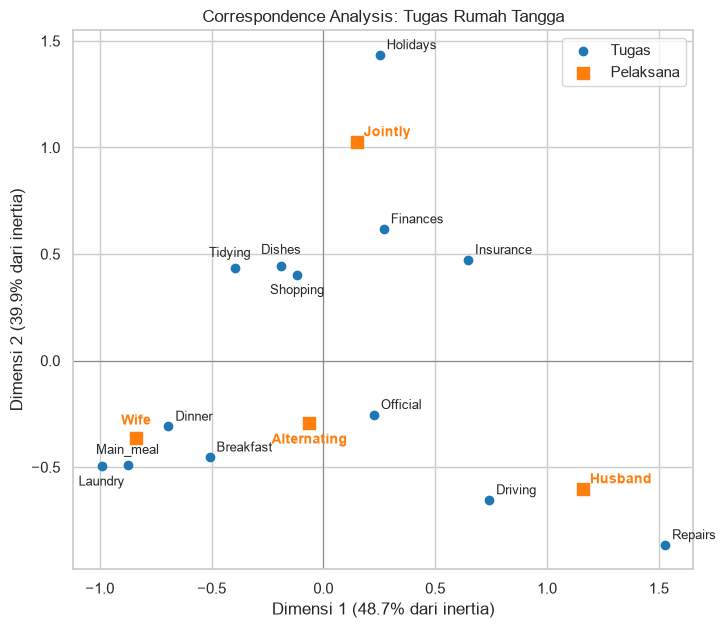

In [12]:
# Posisi label (dalam poin): label yang berdekatan digeser agar tidak saling menimpa.
label_offsets = {
    "Laundry": (0, -14),
    "Main_meal": (0, 8),
    "Wife": (0, 10),
    "Tidying": (-4, 8),
    "Dishes": (0, 9),
    "Shopping": (0, -14),
    "Alternating": (0, -15),
}


def add_label(ax, name, x, y, **style):
    dx, dy = label_offsets.get(name, (5, 4))
    alignment = "center" if name in label_offsets else "left"
    ax.annotate(name, (x, y), textcoords="offset points", xytext=(dx, dy), ha=alignment, **style)


fig, ax = plt.subplots(figsize=(8, 7))

ax.scatter(row_coordinates[0], row_coordinates[1], color="tab:blue", label="Tugas")
ax.scatter(
    column_coordinates[0], column_coordinates[1],
    color="tab:orange", marker="s", s=80, label="Pelaksana"
)

for name, row in row_coordinates.iterrows():
    add_label(ax, name, row[0], row[1], fontsize=9)

for name, row in column_coordinates.iterrows():
    add_label(ax, name, row[0], row[1], fontsize=10, color="tab:orange", fontweight="bold")

ax.axhline(0, color="#888888", linewidth=0.8)
ax.axvline(0, color="#888888", linewidth=0.8)
ax.set_xlabel(f"Dimensi 1 ({explained_inertia[0]:.1%} dari inertia)")
ax.set_ylabel(f"Dimensi 2 ({explained_inertia[1]:.1%} dari inertia)")
ax.set_title("Correspondence Analysis: Tugas Rumah Tangga")
ax.legend()

plt.show()

### Interpretasi

Total inertia (1.1149) sama dengan statistik chi-square dibagi jumlah
observasi, sebagaimana seharusnya. Dimensi 1 menjelaskan 48.7% inertia
dan Dimensi 2 39.9%, sehingga kedua dimensi mencakup 88.6% informasi
pada tabel.

Dimensi 1 membentang dari Wife (-0.838) ke Husband (1.161). Tugas yang
dekat dengan Wife adalah Laundry (-0.992), Main_meal (-0.876), Dinner
(-0.693), dan Breakfast (-0.509), sedangkan tugas yang dekat dengan
Husband adalah Repairs (1.529), Driving (0.742), dan Insurance (0.647).

Dimensi 2 membedakan tugas yang dikerjakan bersama dari tugas yang
dikerjakan satu pihak. Jointly (1.027) berdekatan dengan Holidays
(1.435), Finances (0.618), serta Dishes, Tidying, dan Shopping (sekitar
0.4), sedangkan Wife dan Husband berada di sisi negatif. Alternating
berada dekat nol pada Dimensi 1, artinya tugas yang dikerjakan
bergantian tidak condong ke istri maupun suami.

Kedekatan titik mencerminkan asosiasi pada tabel: Holidays hampir selalu
dikerjakan bersama (153 dari 160 rumah tangga) dan Repairs hampir selalu
dikerjakan suami (160 dari 165 rumah tangga).

## 4. K-Means Clustering

K-means membagi data menjadi K kelompok (cluster) sehingga jumlah kuadrat jarak setiap observasi ke pusat (centroid) cluster-nya sekecil mungkin. Algoritmanya dimulai dari K pusat awal, lalu berulang kali menugaskan setiap observasi ke pusat terdekat dan menghitung ulang pusat setiap cluster hingga hasilnya stabil. Ukuran kualitas yang dipakai adalah inertia, yaitu jumlah kuadrat jarak tersebut.

Hasil K-means bergantung pada pusat awal. Karena itu algoritma dijalankan 10 kali (`n_init=10`) dengan pusat awal yang berbeda dan hasil dengan inertia terkecil dipilih. Nomor cluster bersifat sembarang, sehingga cluster pada notebook ini diurutkan dari yang terbesar. Walaupun `random_state` ditetapkan, ukuran cluster dapat sedikit berbeda pada versi scikit-learn yang berbeda.

In [13]:
def order_by_size(model):
    """Urutkan cluster dari yang terbesar: kembalikan label baru dan pusat cluster yang sudah terurut."""
    order = np.argsort(-np.bincount(model.labels_))
    new_label = {old: new for new, old in enumerate(order)}
    labels = np.array([new_label[label] for label in model.labels_])
    return labels, model.cluster_centers_[order]

### Contoh Sederhana: XOM dan CVX

K-means dengan K = 4 diterapkan pada perubahan harga harian XOM dan CVX sejak 1 Januari 2011.

In [14]:
oil_recent = sp500_px.loc[sp500_px.index >= "2011-01-01", ["XOM", "CVX"]].copy()

kmeans_oil = KMeans(n_clusters=4, n_init=10, random_state=1).fit(oil_recent)
oil_recent["cluster"], centers = order_by_size(kmeans_oil)

centers_oil = pd.DataFrame(centers, columns=["XOM", "CVX"])
centers_oil["size"] = oil_recent["cluster"].value_counts().sort_index().to_numpy()

stability = [
    adjusted_rand_score(
        kmeans_oil.labels_,
        KMeans(n_clusters=4, n_init=10, random_state=seed).fit(oil_recent[["XOM", "CVX"]]).labels_
    )
    for seed in range(2, 7)
]

print(oil_recent.head())
print("\nPusat cluster (terurut menurut ukuran):")
print(centers_oil)
print(f"\nInertia: {kmeans_oil.inertia_:,.1f}")
print(f"Kemiripan dengan hasil yang memakai pusat awal lain (adjusted Rand index): {min(stability):.3f} sampai {max(stability):.3f}")

             XOM    CVX  cluster
2011-01-03 0.737  0.241        0
2011-01-04 0.169 -0.585        1
2011-01-05 0.027  0.447        0
2011-01-06 0.249 -0.920        1
2011-01-07 0.337  0.181        0

Pusat cluster (terurut menurut ukuran):
     XOM    CVX  size
0  0.242  0.335   465
1 -0.328 -0.567   374
2  0.958  1.374   180
3 -1.144 -1.750   112

Inertia: 408.8
Kemiripan dengan hasil yang memakai pusat awal lain (adjusted Rand index): 0.958 sampai 0.998


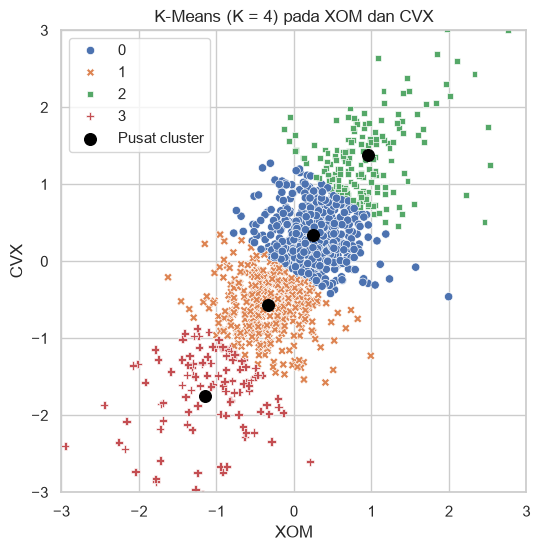

In [15]:
fig, ax = plt.subplots(figsize=(6, 6))

sns.scatterplot(
    data=oil_recent, x="XOM", y="CVX",
    hue="cluster", style="cluster", palette="deep", ax=ax
)
ax.scatter(centers_oil["XOM"], centers_oil["CVX"], color="black", s=70, label="Pusat cluster")

ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.set_title("K-Means (K = 4) pada XOM dan CVX")
ax.legend()

plt.show()

### Interpretasi

K-means membagi awan titik XOM dan CVX menjadi empat kelompok hari: 465
hari dengan kenaikan ringan (pusat XOM 0.242 dan CVX 0.335), 374 hari
dengan penurunan ringan (-0.328 dan -0.567), 180 hari dengan kenaikan
besar (0.958 dan 1.374), dan 112 hari dengan penurunan besar (-1.144 dan
-1.750). Seluruh pusat berada di sepanjang diagonal karena kedua saham
bergerak searah, dan CVX bergerak sedikit lebih besar daripada XOM pada
setiap cluster.

Data ini berupa satu awan yang kontinu tanpa kelompok yang terpisah
jelas, sehingga K-means hanya membagi awan tersebut menjadi potongan
menurut arah dan besar pergerakan. Pembagian ini berguna sebagai
ringkasan (hari naik atau turun, ringan atau besar), tetapi batas antar-
cluster bersifat buatan. Hasilnya stabil terhadap pusat awal: dengan
lima pusat awal lain, kemiripan pembagian cluster (adjusted Rand index;
1 berarti identik) berkisar 0.958 sampai 0.998.

### Menafsirkan Cluster pada Banyak Saham

K-means dengan K = 5 diterapkan pada 16 saham yang sama seperti pada PCA. Setiap hari perdagangan adalah satu observasi, sehingga cluster mengelompokkan hari-hari dengan pola pergerakan harga yang mirip. Pusat setiap cluster menunjukkan rata-rata perubahan harga setiap saham pada hari-hari tersebut.

In [16]:
kmeans_sp = KMeans(n_clusters=5, n_init=10, random_state=1).fit(top_sp)
labels_sp, centers_values = order_by_size(kmeans_sp)

centers_sp = pd.DataFrame(
    centers_values,
    columns=symbols,
    index=[f"Cluster {i + 1}" for i in range(5)]
)

stability_sp = [
    adjusted_rand_score(kmeans_sp.labels_, KMeans(n_clusters=5, n_init=10, random_state=seed).fit(top_sp).labels_)
    for seed in range(2, 7)
]

print("Ukuran cluster:", dict(zip(centers_sp.index, np.bincount(labels_sp).tolist())))
print(f"Kemiripan dengan hasil yang memakai pusat awal lain (adjusted Rand index): {min(stability_sp):.3f} sampai {max(stability_sp):.3f}\n")
print(centers_sp.transpose())

Ukuran cluster: {'Cluster 1': 301, 'Cluster 2': 287, 'Cluster 3': 272, 'Cluster 4': 158, 'Cluster 5': 113}
Kemiripan dengan hasil yang memakai pusat awal lain (adjusted Rand index): 0.849 sampai 0.918

      Cluster 1  Cluster 2  Cluster 3  Cluster 4  Cluster 5
AAPL      0.712     -0.421     -0.322      0.516     -1.221
AXP       0.301      0.013     -0.194      0.561     -0.977
COP       0.071      0.211     -0.396      0.672     -0.861
COST      0.417     -0.251     -0.061      0.688     -1.081
CSCO      0.082      0.010     -0.057      0.159     -0.220
CVX       0.102      0.369     -0.660      1.232     -1.385
HD        0.375     -0.180     -0.088      0.541     -0.749
INTC      0.099      0.023     -0.056      0.214     -0.293
JPM       0.165      0.035     -0.123      0.477     -0.783
MSFT      0.123     -0.013     -0.056      0.280     -0.391
SLB       0.016      0.409     -0.836      1.471     -1.420
TGT       0.307     -0.149     -0.073      0.304     -0.604
USB       0.113   

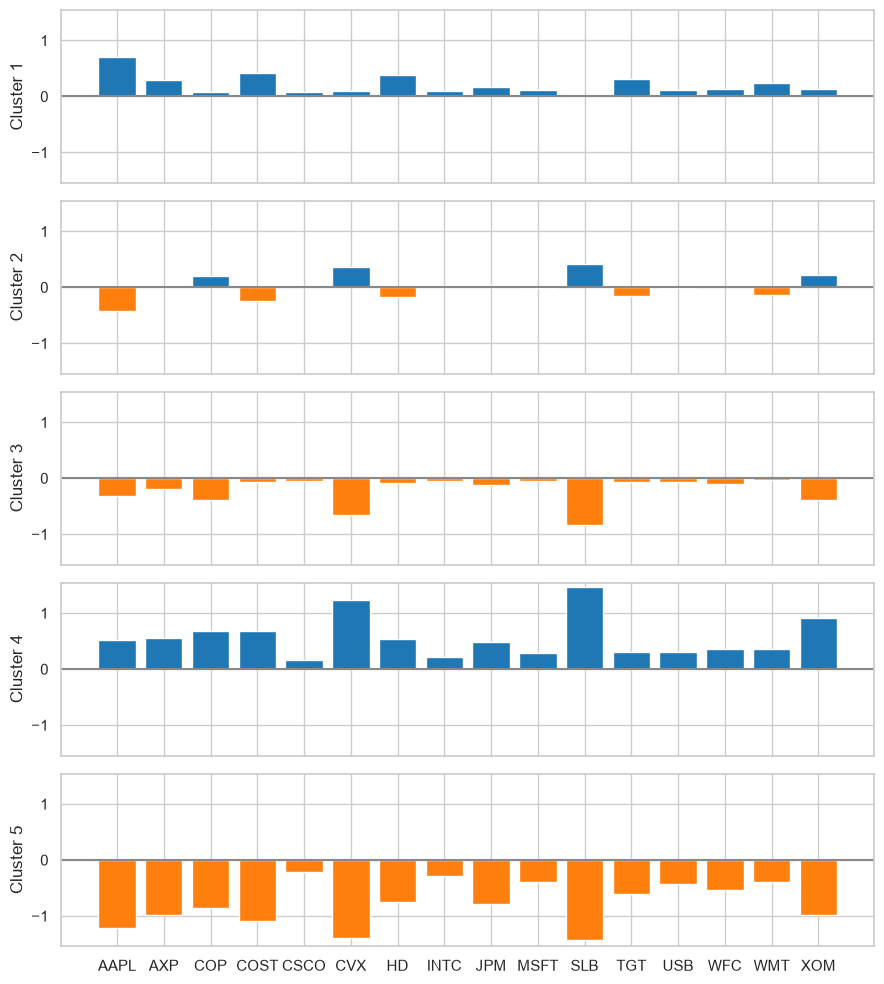

In [17]:
limit = 1.05 * centers_sp.abs().to_numpy().max()

fig, axes = plt.subplots(5, 1, figsize=(9, 10), sharex=True)

for ax, (name, row) in zip(axes, centers_sp.iterrows()):
    colors = ["tab:blue" if value > 0 else "tab:orange" for value in row]

    ax.axhline(0, color="#888888")
    ax.bar(row.index, row.values, color=colors)
    ax.set_ylabel(name)
    ax.set_ylim(-limit, limit)

plt.tight_layout()
plt.show()

### Interpretasi

Kelima cluster mengelompokkan hari menurut pola pergerakan harga:

- **Cluster 1 (301 hari):** saham konsumen dan Apple naik moderat (AAPL
  0.712, COST 0.417, HD 0.375) sementara saham energi hampir datar (SLB
  0.016 dan CVX 0.102).
- **Cluster 2 (287 hari):** saham energi naik (SLB 0.409, CVX 0.369,
  XOM 0.226) sementara AAPL, COST, dan HD turun (-0.421, -0.251, dan
  -0.180).
- **Cluster 3 (272 hari):** penurunan khusus saham energi (SLB -0.836,
  CVX -0.660, COP -0.396, XOM -0.391) dengan saham lain hampir datar.
- **Cluster 4 (158 hari):** kenaikan luas pada semua saham, terbesar pada
  energi (SLB 1.471, CVX 1.232, XOM 0.921).
- **Cluster 5 (113 hari):** penurunan luas pada semua saham, terbesar
  pada SLB (-1.420), CVX (-1.385), dan AAPL (-1.221).

Cluster 4 dan 5 sesuai dengan PC1 (gerakan pasar secara keseluruhan),
sedangkan Cluster 1 sampai 3 sesuai dengan PC2 (energi berlawanan dengan
konsumen). Hasilnya cukup stabil terhadap pusat awal (adjusted Rand
index 0.849 sampai 0.918 terhadap lima pusat awal lain), tetapi tidak
identik: sebagian hari pada batas antar-cluster berpindah cluster.

### Memilih Jumlah Cluster

Jumlah cluster K harus ditentukan sebelum K-means dijalankan. Salah satu cara adalah elbow method: K-means dijalankan untuk beberapa nilai K dan inertia dibandingkan. Inertia selalu turun ketika K bertambah, sehingga K dipilih pada titik ketika penurunan tidak lagi tajam (siku).

 k  Total inertia  Inertia per cluster
 2      6,063.300            3,031.600
 3      5,379.600            1,793.200
 4      4,992.500            1,248.100
 5      4,714.400              942.900
 6      4,503.800              750.600
 7      4,318.000              616.900
 8      4,181.200              522.700
 9      4,065.700              451.700
10      3,965.800              396.600
11      3,880.900              352.800
12      3,798.200              316.500
13      3,723.800              286.400
14      3,662.500              261.600


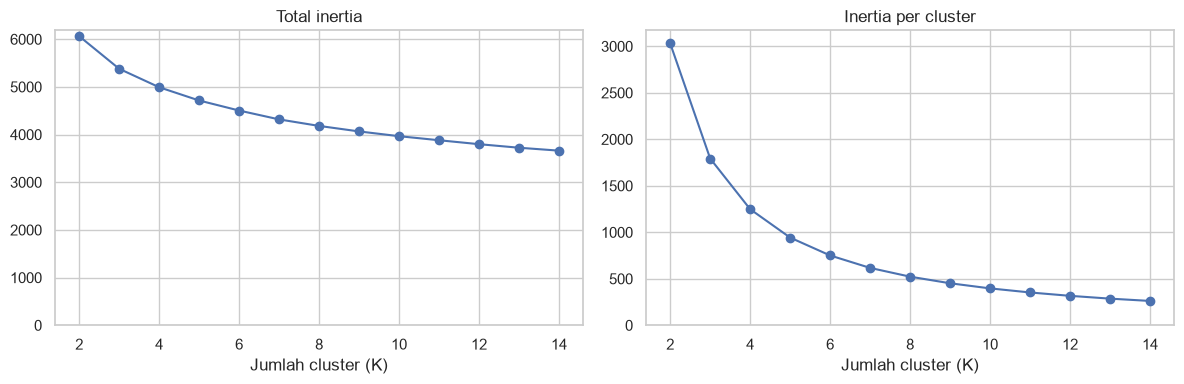

In [18]:
k_values = list(range(2, 15))
total_inertia = []

for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=1).fit(top_sp)
    total_inertia.append(model.inertia_)

elbow = pd.DataFrame({"k": k_values, "Total inertia": total_inertia})
elbow["Inertia per cluster"] = elbow["Total inertia"] / elbow["k"]

print(elbow.round(1).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(elbow["k"], elbow["Total inertia"], marker="o")
axes[0].set_title("Total inertia")

axes[1].plot(elbow["k"], elbow["Inertia per cluster"], marker="o")
axes[1].set_title("Inertia per cluster")

for ax in axes:
    ax.set_xlabel("Jumlah cluster (K)")
    ax.set_ylim(0, None)

plt.tight_layout()
plt.show()

### Interpretasi

Total inertia turun terus dari 6,063.3 pada K = 2 menjadi 3,662.5 pada
K = 14, dan penurunannya mengecil secara bertahap tanpa siku yang tajam.
Inertia per cluster turun cepat sampai K sekitar 4 sampai 6 (1,248.1
pada K = 4, 942.9 pada K = 5, dan 750.6 pada K = 6), kemudian melandai,
tetapi tidak ada titik yang jelas sebagai siku.

Pada data pasar saham yang kontinu tidak ada jumlah cluster alami yang
jelas. Pemilihan K lebih baik mengikuti kemudahan menafsirkan cluster
dan tujuan analisis. K = 5 menghasilkan cluster yang masing-masing dapat
dijelaskan (bagian sebelumnya), sedangkan K yang jauh lebih besar
menghasilkan cluster yang semakin sulit dibedakan.

## 5. Hierarchical Clustering

Hierarchical clustering tidak memerlukan jumlah cluster di awal. Pada metode agglomerative, setiap observasi dimulai sebagai cluster sendiri, lalu dua cluster yang paling mirip digabung berulang kali hingga tersisa satu cluster. Urutan penggabungan digambarkan sebagai dendrogram, dan jumlah cluster ditentukan kemudian dengan memotong dendrogram pada tinggi tertentu.

Kemiripan antarcluster diukur dengan metode linkage, misalnya:

- **single:** jarak terdekat antara dua observasi dari kedua cluster.
- **complete:** jarak terjauh antara dua observasi dari kedua cluster.
- **average:** rata-rata seluruh jarak antarobservasi.
- **ward:** penggabungan yang menambah jumlah kuadrat jarak dalam cluster sekecil mungkin.

### Dendrogram

Pada contoh ini, yang dikelompokkan adalah saham, bukan hari. Setiap saham dinyatakan oleh deretan perubahan harian sejak 1 Januari 2011, sehingga jarak antarsaham mengukur kemiripan pergerakan harganya. Linkage yang dipakai adalah complete.

In [19]:
symbols_h = [
    "AAPL", "AMZN", "AXP", "COP", "COST", "CSCO", "CVX", "GOOGL", "HD",
    "INTC", "JPM", "MSFT", "SLB", "TGT", "USB", "WFC", "WMT", "XOM"
]

returns_h = sp500_px.loc[sp500_px.index >= "2011-01-01", symbols_h].transpose()

linkage_complete = linkage(returns_h, method="complete")
membership = pd.Series(
    fcluster(linkage_complete, 4, criterion="maxclust"),
    index=returns_h.index
)

print("Bentuk matriks linkage (n - 1 penggabungan):", linkage_complete.shape)
print("Tinggi empat penggabungan terakhir:", linkage_complete[-4:, 2].round(1).tolist())
print()

for cluster_id, members in membership.groupby(membership):
    print(f"Cluster {cluster_id}: {', '.join(members.index)}")

Bentuk matriks linkage (n - 1 penggabungan): (17, 4)
Tinggi empat penggabungan terakhir: [39.0, 43.2, 136.3, 157.4]

Cluster 1: COP, CVX, SLB, XOM
Cluster 2: AAPL, AXP, COST, CSCO, HD, INTC, JPM, MSFT, TGT, USB, WFC, WMT
Cluster 3: AMZN
Cluster 4: GOOGL


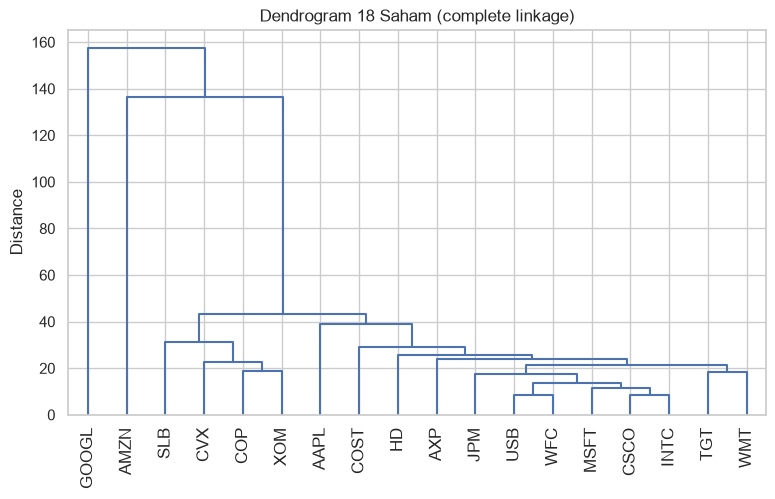

In [20]:
fig, ax = plt.subplots(figsize=(9, 5))

dendrogram(linkage_complete, labels=list(returns_h.index), color_threshold=0, ax=ax)

ax.set_ylabel("Distance")
ax.set_title("Dendrogram 18 Saham (complete linkage)")

plt.xticks(rotation=90)
plt.show()

### Interpretasi

Dendrogram memperlihatkan dua kelompok saham dan dua saham yang berdiri
sendiri. Keempat saham energi (SLB, CVX, COP, dan XOM) saling bergabung
pada ketinggian di bawah 32 dan membentuk Cluster 1. Dua belas saham
teknologi, keuangan, dan ritel (AAPL, AXP, COST, CSCO, HD, INTC, JPM,
MSFT, TGT, USB, WFC, dan WMT) membentuk Cluster 2 dan baru bergabung
dengan kelompok energi pada ketinggian 43.2. AMZN dan GOOGL masing-masing
menjadi cluster sendiri karena bergabung pada ketinggian yang jauh lebih
besar (136.3 dan 157.4).

Jarak Euclidean pada perubahan harga mengukur besar dan arah gerakan,
sehingga saham yang fluktuasinya sangat besar seperti GOOGL dan AMZN
berada jauh dari semua saham lain dan terpisah sebagai cluster tersendiri
bukan karena sektornya. Kelompok energi terpisah dari saham lain karena
gerakannya serupa satu sama lain dan lebih besar daripada saham pada
Cluster 2. Bila yang diinginkan adalah kemiripan pola gerakan tanpa
memedulikan besarnya fluktuasi, saham sebaiknya distandardisasi lebih
dulu (bagian 7).

### Ukuran Ketidakmiripan (Linkage)

Pilihan linkage memengaruhi bentuk cluster. Empat metode dibandingkan pada perubahan harian XOM dan CVX sejak 2011 dengan memotong dendrogram menjadi 4 cluster.

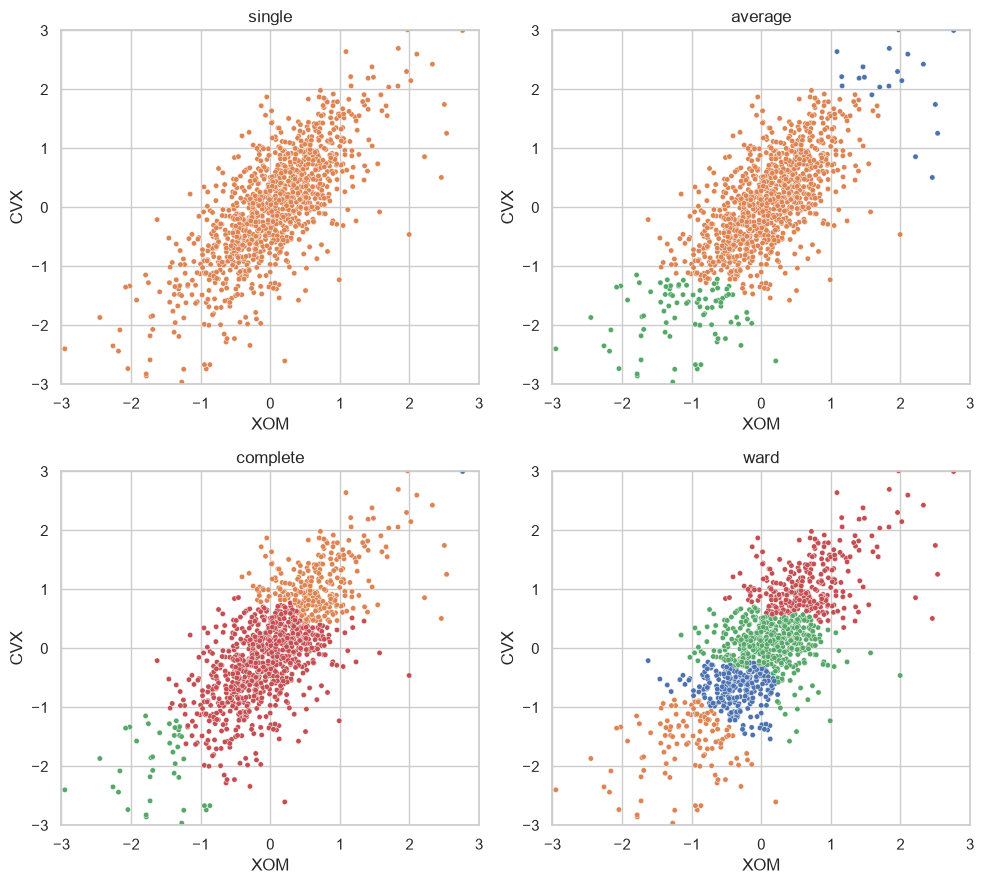

Ukuran keempat cluster (terurut dari terbesar):
  single   : [1127, 2, 1, 1]
  average  : [1015, 91, 24, 1]
  complete : [805, 277, 44, 5]
  ward     : [464, 290, 254, 123]


In [21]:
oil_xy = sp500_px.loc[sp500_px.index >= "2011-01-01", ["XOM", "CVX"]]

linkage_methods = ["single", "average", "complete", "ward"]
cluster_sizes = {}

fig, axes = plt.subplots(2, 2, figsize=(10, 9))

for ax, method in zip(axes.ravel(), linkage_methods):
    labels = fcluster(linkage(oil_xy, method=method), 4, criterion="maxclust")
    cluster_sizes[method] = np.sort(np.bincount(labels)[1:])[::-1].tolist()

    sns.scatterplot(
        x=oil_xy["XOM"], y=oil_xy["CVX"],
        hue=labels, palette="deep", s=15, legend=False, ax=ax
    )
    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    ax.set_title(method)

plt.tight_layout()
plt.show()

print("Ukuran keempat cluster (terurut dari terbesar):")
for method, sizes in cluster_sizes.items():
    print(f"  {method:9s}: {sizes}")

### Interpretasi

Pilihan linkage sangat memengaruhi ukuran dan bentuk cluster pada data
yang sama. Single linkage menghasilkan satu cluster berisi 1,127 dari
1,131 hari dan tiga cluster yang hanya berisi 1 sampai 2 titik terluar.
Gejala ini disebut chaining: cluster terus menyambung melalui titik-titik
yang berdekatan sehingga satu cluster membesar. Average linkage juga
menyisakan satu cluster dominan (1,015 hari) dengan cluster kecil di
tepi. Complete linkage lebih kompak tetapi tidak seimbang (805, 277, 44,
dan 5), sedangkan Ward menghasilkan empat cluster yang paling seimbang
(464, 290, 254, dan 123 hari) dan mirip dengan hasil K-means.

Tidak ada linkage yang benar untuk semua data. Single linkage cocok bila
cluster berbentuk rantai memanjang, sedangkan complete linkage dan Ward
menghasilkan cluster yang kompak. Pilihannya sebaiknya mengikuti bentuk
cluster yang diharapkan dan diperiksa dengan visualisasi.

## 6. Model-Based Clustering

Model-based clustering menganggap data berasal dari campuran beberapa distribusi probabilitas, umumnya distribusi normal multivariat. Setiap cluster adalah satu komponen campuran dengan rata-rata, matriks kovarians, dan bobot (proporsi) sendiri. Berbeda dengan K-means yang memakai jarak ke pusat, metode ini memodelkan bentuk dan sebaran setiap cluster sehingga cluster dapat berbentuk elips dan berukuran berbeda.

### Distribusi Normal Multivariat

Distribusi normal dua variabel ditentukan oleh vektor rata-rata dan matriks kovarians. Kontur kepadatan berbentuk elips; elips yang lebih luar melingkupi proporsi data yang lebih besar. Pada contoh ini rata-ratanya (0.5, -0.5) dan kovariansnya [[1, 1], [1, 2]], dengan kontur yang melingkupi 50%, 75%, 95%, dan 99% data.

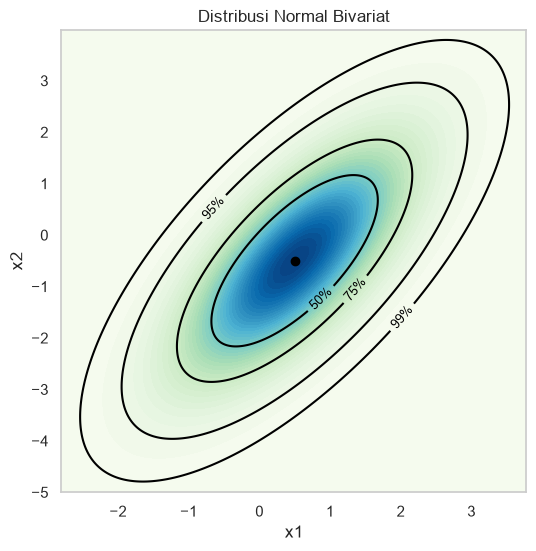

Proporsi sampel simulasi yang berada di dalam kontur:
  Kontur 99%: 0.989
  Kontur 95%: 0.950
  Kontur 75%: 0.752
  Kontur 50%: 0.502


In [22]:
mean = [0.5, -0.5]
covariance = [[1, 1], [1, 2]]
probabilities = sorted([0.5, 0.75, 0.95, 0.99], reverse=True)

determinant_root = np.sqrt(np.linalg.det(covariance))
levels = sorted((1 - p) / (2 * np.pi * determinant_root) for p in probabilities)

grid_x, grid_y = np.mgrid[-2.8:3.8:0.02, -5:4:0.02]
density = multivariate_normal(mean, covariance).pdf(np.dstack((grid_x, grid_y)))

fig, ax = plt.subplots(figsize=(6, 6))

ax.contourf(grid_x, grid_y, density, cmap="GnBu", levels=50)
contours = ax.contour(grid_x, grid_y, density, levels=levels, colors="black")
ax.clabel(contours, fmt={level: f"{p:.0%}" for level, p in zip(levels, probabilities)}, fontsize=9)
ax.plot(*mean, color="black", marker="o")

ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_title("Distribusi Normal Bivariat")

plt.show()

rng = np.random.default_rng(1)
sample = rng.multivariate_normal(mean, covariance, size=100_000)
sample_density = multivariate_normal(mean, covariance).pdf(sample)

print("Proporsi sampel simulasi yang berada di dalam kontur:")
for p, level in zip(probabilities, levels):
    print(f"  Kontur {p:.0%}: {np.mean(sample_density >= level):.3f}")

### Interpretasi

Kontur berbentuk elips yang miring ke kanan atas karena kovarians kedua
variabel positif (kovarians 1 dengan variance 1 dan 2, sehingga
korelasinya 0.71). Kontur 50% melingkupi bagian tengah data, sedangkan
kontur 99% melingkupi hampir seluruh data.

Simulasi 100,000 titik dari distribusi ini memperlihatkan bahwa proporsi
titik di dalam setiap kontur sangat dekat dengan probabilitasnya (0.502
untuk 50%, 0.752 untuk 75%, 0.950 untuk 95%, dan 0.989 untuk 99%),
sehingga kontur pada gambar benar menyatakan wilayah dengan peluang
tersebut. Bentuk elips inilah yang membuat model-based clustering dapat
menangkap cluster dengan arah dan sebaran berbeda, berbeda dengan K-means
yang cenderung membentuk cluster bulat.

### Mixture of Normals

Campuran dua distribusi normal dipasang pada perubahan harian XOM dan CVX sejak 2011 dengan `GaussianMixture`. Parameternya diestimasi dengan algoritma expectation-maximization (EM). Hasilnya diurutkan menurut bobot komponen, dan Bayesian Information Criterion (BIC) dihitung sebagai ukuran kecocokan model yang memperhitungkan jumlah parameter; pada scikit-learn, BIC yang lebih kecil berarti model yang lebih baik.

In [23]:
mclust = GaussianMixture(n_components=2, n_init=5, random_state=1).fit(oil_xy)

order = np.argsort(-mclust.weights_)
mixture_labels = np.array([int(np.where(order == label)[0][0]) for label in mclust.predict(oil_xy)])

print(f"BIC: {mclust.bic(oil_xy):,.1f}")
print(f"Jumlah hari pada setiap komponen: {np.bincount(mixture_labels).tolist()}\n")

print("Rata-rata:")
print(pd.DataFrame(
    mclust.means_[order],
    columns=["XOM", "CVX"],
    index=["Komponen 1", "Komponen 2"]
))

print("\nBobot, simpangan baku, dan korelasi:")
for rank, component in enumerate(order, start=1):
    covariance_matrix = mclust.covariances_[component]
    std = np.sqrt(np.diag(covariance_matrix))
    correlation = covariance_matrix[0, 1] / (std[0] * std[1])
    print(
        f"  Komponen {rank}: bobot {mclust.weights_[component]:.3f} | "
        f"std XOM {std[0]:.3f} | std CVX {std[1]:.3f} | korelasi {correlation:.3f}"
    )

BIC: 4,589.3
Jumlah hari pada setiap komponen: [924, 207]

Rata-rata:
              XOM    CVX
Komponen 1  0.071  0.102
Komponen 2 -0.051 -0.215

Bobot, simpangan baku, dan korelasi:
  Komponen 1: bobot 0.665 | std XOM 0.520 | std CVX 0.722 | korelasi 0.740
  Komponen 2: bobot 0.335 | std XOM 0.993 | std CVX 1.303 | korelasi 0.768


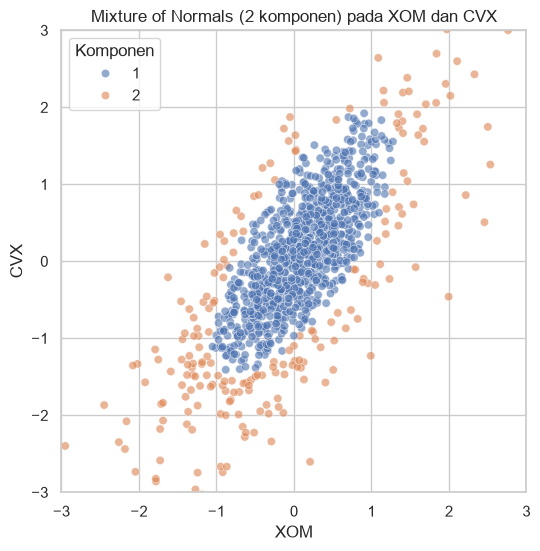

In [24]:
fig, ax = plt.subplots(figsize=(6, 6))

sns.scatterplot(
    x=oil_xy["XOM"], y=oil_xy["CVX"],
    hue=mixture_labels + 1, palette="deep", alpha=0.6, ax=ax
)

ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.set_title("Mixture of Normals (2 komponen) pada XOM dan CVX")
ax.legend(title="Komponen")

plt.show()

### Interpretasi

Dua komponen memisahkan hari-hari menurut volatilitasnya, bukan menurut
arah gerakannya. Rata-rata kedua komponen sama-sama dekat nol (XOM 0.071
dan -0.051; CVX 0.102 dan -0.215), tetapi sebarannya sangat berbeda.
Komponen 1 (bobot 0.665; 924 hari) adalah hari-hari tenang dengan
simpangan baku XOM 0.520 dan CVX 0.722. Komponen 2 (bobot 0.335; 207
hari) adalah hari-hari bergejolak dengan simpangan baku hampir dua kali
lipat (XOM 0.993 dan CVX 1.303). Korelasi XOM dan CVX tinggi pada kedua
komponen (0.740 dan 0.768): kedua saham tetap bergerak searah pada hari
tenang maupun bergejolak.

Hal ini berbeda dari K-means yang membagi data menurut pusat yang
berjauhan. Pada mixture, komponen bergejolak adalah pinggiran awan yang
mengelilingi komponen tenang di tengah (lihat gambar). Bobot komponen 2
(0.335) lebih besar daripada proporsi hari yang ditugaskan padanya
(207 dari 1,131 hari, atau 18.3%) karena komponen yang lebar juga
memiliki massa probabilitas di bagian tengah awan, tempat setiap titik
ditugaskan ke komponen tenang yang kepadatannya lebih tinggi. BIC model
ini adalah 4,589.3.

### Memilih Jumlah Komponen dengan BIC

Jumlah komponen dan bentuk matriks kovarians dipilih dengan membandingkan BIC. Empat jenis kovarians dicoba: `full` (setiap komponen memiliki kovarians bebas), `tied` (semua komponen berbagi satu kovarians), `diag` (kovarians diagonal), dan `spherical` (variance sama pada semua variabel).

covariance_type      diag      full  spherical      tied
n_components                                            
1               5,623.000 4,662.000  5,717.000 4,662.000
2               5,295.000 4,589.000  5,349.000 4,689.000
3               4,986.000 4,635.000  5,003.000 4,687.000
4               4,781.000 4,670.000  4,785.000 4,661.000
5               4,741.000 4,715.000  4,719.000 4,690.000
6               4,739.000 4,752.000  4,702.000 4,714.000
7               4,770.000 4,793.000  4,731.000 4,737.000
8               4,801.000 4,835.000  4,755.000 4,737.000

BIC terendah: 4,589.3 (n_components = 2, covariance_type = full)


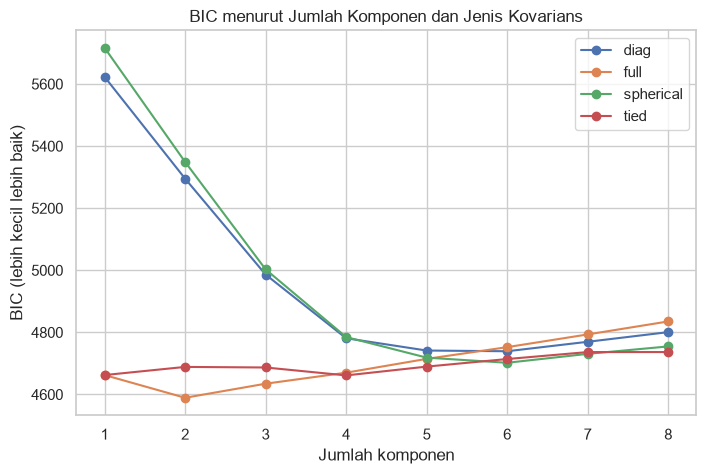

In [25]:
results = []

for n_components in range(1, 9):
    for covariance_type in ["full", "tied", "diag", "spherical"]:
        model = GaussianMixture(
            n_components=n_components,
            covariance_type=covariance_type,
            n_init=3,
            random_state=1
        )
        model.fit(oil_xy)

        results.append({
            "n_components": n_components,
            "covariance_type": covariance_type,
            "bic": model.bic(oil_xy),
        })

results = pd.DataFrame(results)
bic_table = results.pivot(index="n_components", columns="covariance_type", values="bic")

print(bic_table.round(0))

best = results.loc[results["bic"].idxmin()]
print(
    f"\nBIC terendah: {best['bic']:,.1f} "
    f"(n_components = {int(best['n_components'])}, covariance_type = {best['covariance_type']})"
)

plt.figure(figsize=(8, 5))

for covariance_type in bic_table.columns:
    plt.plot(bic_table.index, bic_table[covariance_type], marker="o", label=covariance_type)

plt.xlabel("Jumlah komponen")
plt.ylabel("BIC (lebih kecil lebih baik)")
plt.title("BIC menurut Jumlah Komponen dan Jenis Kovarians")
plt.legend()

plt.show()

### Interpretasi

BIC terendah (4,589.3) diperoleh pada dua komponen dengan kovarians
`full`. Pada kovarians `full`, BIC turun dari 4,662 (satu komponen) ke
4,589 (dua komponen), lalu naik lagi menjadi 4,635 (tiga komponen) dan
seterusnya. Penambahan komponen setelah dua tidak memperbaiki kecocokan
cukup besar untuk menutupi penalti jumlah parameter.

Jenis kovarians yang lebih sederhana (`diag` dan `spherical`)
memerlukan lima sampai enam komponen untuk mendekati kecocokan yang
sama, dan BIC terbaiknya (4,702 sampai 4,739) tetap lebih buruk. Model
`tied` dengan empat komponen (4,661) hampir sama dengan model satu
komponen (4,662).

Hasil ini sejalan dengan temuan sebelumnya: struktur terpenting pada data
XOM dan CVX adalah dua kelompok hari dengan variance berbeda, bukan
beberapa kelompok yang terpisah jauh.

## 7. Penskalaan Variabel dan Data Kategorikal

Metode yang berbasis jarak atau variance, seperti K-means dan PCA, sangat dipengaruhi oleh skala variabel. Data kategorikal juga tidak dapat dipakai langsung karena jarak antarkategori tidak didefinisikan. Bagian ini memperlihatkan masalah tersebut dan cara mengatasinya.

### Penskalaan Variabel pada K-Means

K-means dengan K = 4 diterapkan pada pinjaman yang gagal bayar (`default`) memakai enam variabel numerik: `loan_amnt`, `annual_inc`, `revol_bal`, `open_acc`, `dti`, dan `revol_util`. Hasilnya dibandingkan antara data asli dan data yang sudah distandardisasi (z-score). Pusat cluster pada data yang distandardisasi dikembalikan ke skala asli agar dapat dibaca.

In [26]:
defaults = loan_data.loc[loan_data["outcome"] == "default"]

columns = ["loan_amnt", "annual_inc", "revol_bal", "open_acc", "dti", "revol_util"]
features = defaults[columns]


def summarize(model, centers):
    order = np.argsort(-np.bincount(model.labels_))
    summary = pd.DataFrame(centers[order], columns=columns)
    summary["size"] = np.bincount(model.labels_)[order]
    return summary


kmeans_raw = KMeans(n_clusters=4, n_init=10, random_state=1).fit(features)

scaler = StandardScaler()
scaled_features = scaler.fit_transform(features * 1.0)
kmeans_scaled = KMeans(n_clusters=4, n_init=10, random_state=1).fit(scaled_features)

print(f"Jumlah pinjaman default: {len(features):,}")
print("\nSimpangan baku setiap variabel:")
print(features.std().map("{:,.1f}".format).to_string())

print("\nTanpa penskalaan:")
print(summarize(kmeans_raw, kmeans_raw.cluster_centers_))

print("\nDengan standardisasi (pusat dikembalikan ke skala asli):")
print(summarize(kmeans_scaled, scaler.inverse_transform(kmeans_scaled.cluster_centers_)))

Jumlah pinjaman default: 22,671

Simpangan baku setiap variabel:
loan_amnt      8,329.8
annual_inc    41,108.6
revol_bal     19,416.1
open_acc           4.7
dti                7.7
revol_util        24.5

Tanpa penskalaan:
   loan_amnt  annual_inc  revol_bal  open_acc    dti  revol_util   size
0 10,622.743  42,577.469 10,301.719     9.594 17.708      58.125  13949
1 18,312.358  83,793.804 19,740.573    11.678 16.772      62.307   7509
2 21,924.589 166,721.916 39,129.990    12.566 13.375      63.505   1161
3 22,570.192 489,783.404 85,161.346    13.327  6.907      59.652     52

Dengan standardisasi (pusat dikembalikan ke skala asli):
   loan_amnt  annual_inc  revol_bal  open_acc    dti  revol_util  size
0 10,475.352  51,152.618 11,505.237     7.473 15.754      77.654  7369
1 13,394.424  55,638.623 16,409.356    14.236 24.233      59.759  6292
2 10,353.683  53,506.668  6,049.699     8.700 11.348      30.578  5306
3 25,911.918 116,436.184 32,850.199    12.417 16.200      66.075  3704


### Interpretasi

Simpangan baku `annual_inc` (41,108.6) dan `revol_bal` (19,416.1) jauh
lebih besar daripada `open_acc` (4.7), `dti` (7.7), dan `revol_util`
(24.5), sehingga pada data asli jarak ditentukan hampir seluruhnya oleh
`annual_inc`, `revol_bal`, dan `loan_amnt` (8,329.8). Tanpa penskalaan,
keempat cluster berbeda terutama pada pendapatan (rata-rata 42,577;
83,794; 166,722; dan 489,783) dan saldo revolving (10,302; 19,741;
39,130; dan 85,161). Variabel lain hampir sama antar-cluster (misalnya
`revol_util` 58.1 sampai 63.5), dan salah satu cluster hanya berisi 52
pinjaman dengan pendapatan sangat tinggi.

Setelah standardisasi, semua variabel berkontribusi setara dan ukuran
cluster lebih seimbang (7,369; 6,292; 5,306; dan 3,704 pinjaman). Cluster
kini dibedakan oleh beberapa variabel sekaligus: satu cluster memiliki
`revol_util` tinggi (77.7), satu memiliki `dti` tinggi (24.2) dan
`open_acc` tinggi (14.2), satu memiliki `revol_util` rendah (30.6), dan
satu lagi berisi pinjaman besar dengan pendapatan tinggi (`loan_amnt`
25,912 dan `annual_inc` 116,436). Standardisasi sebaiknya dilakukan
sebelum K-means, kecuali satuan asli variabel memang bermakna dan ingin
dipertahankan.

### Variabel yang Mendominasi pada PCA

PCA tanpa standardisasi dipengaruhi oleh variabel dengan variance besar. Contohnya adalah 18 saham sejak 1 Januari 2005 yang mencakup GOOGL dan AMZN, dua saham dengan harga per saham yang tinggi sehingga perubahan hariannya (dalam dolar) jauh lebih besar daripada saham lain. PCA pada data asli dibandingkan dengan PCA pada data yang distandardisasi.

In [27]:
symbols_dom = [
    "GOOGL", "AMZN", "AAPL", "MSFT", "CSCO", "INTC", "CVX", "XOM", "SLB",
    "COP", "JPM", "WFC", "USB", "AXP", "WMT", "TGT", "HD", "COST"
]

top_sp1 = sp500_px.loc[sp500_px.index >= "2005-01-01", symbols_dom]

pca_raw = PCA().fit(top_sp1)
pca_std = PCA().fit(StandardScaler().fit_transform(top_sp1))

oriented_raw = orient_components(pca_raw.components_)
oriented_std = orient_components(pca_std.components_)

comparison = pd.DataFrame(
    {
        "Std saham": top_sp1.std(),
        "PC1 asli": oriented_raw[0],
        "PC2 asli": oriented_raw[1],
        "PC1 standardisasi": oriented_std[0],
        "PC2 standardisasi": oriented_std[1],
    },
    index=symbols_dom
)

print(f"Data: {top_sp1.shape[0]} hari x {top_sp1.shape[1]} saham (sejak 2005-01-01)\n")
print(comparison)

print("\nProporsi variance PC1 sampai PC3:")
print("  Tanpa standardisasi  :", pca_raw.explained_variance_ratio_[:3].round(3))
print("  Dengan standardisasi :", pca_std.explained_variance_ratio_[:3].round(3))

Data: 2642 hari x 18 saham (sejak 2005-01-01)

       Std saham  PC1 asli  PC2 asli  PC1 standardisasi  PC2 standardisasi
GOOGL      4.235     0.857    -0.478              0.220             -0.044
AMZN       3.012     0.445     0.874              0.186             -0.045
AAPL       0.723     0.072     0.021              0.176             -0.032
MSFT       0.338     0.036     0.006              0.236             -0.007
CSCO       0.278     0.029     0.003              0.252             -0.034
INTC       0.274     0.027     0.006              0.237             -0.038
CVX        0.952     0.090     0.037              0.253              0.418
XOM        0.853     0.080     0.021              0.257              0.379
SLB        1.254     0.110     0.030              0.216              0.413
COP        0.649     0.058     0.024              0.232              0.457
JPM        0.721     0.071     0.009              0.267             -0.138
WFC        0.552     0.053     0.009              0.2

### Interpretasi

Pada data asli, GOOGL (simpangan baku 4.235) dan AMZN (3.012) memiliki
variance jauh lebih besar daripada saham lain (0.274 sampai 1.254).
Akibatnya dua component pertama hampir seluruhnya mewakili kedua saham
ini: PC1 didominasi GOOGL (loading 0.857) dengan AMZN (0.445), PC2
didominasi AMZN (0.874) berlawanan dengan GOOGL (-0.478), sedangkan
loading semua saham lain kurang dari 0.12. Kedua component menjelaskan
64.7% dan 17.2% variance, tetapi sebagian besar karena variance kedua
saham tersebut, bukan karena pola bersama seluruh pasar.

Setelah standardisasi, setiap saham memiliki variance yang sama. PC1
kini memiliki loading yang hampir sama untuk semua 18 saham (0.176
sampai 0.267), yaitu gerakan pasar secara keseluruhan, dan menjelaskan
44.6% variance. PC2 (9.6%) membedakan saham energi (COP 0.457, CVX
0.418, SLB 0.413, dan XOM 0.379) dari saham ritel dan keuangan (TGT
-0.254, WMT -0.231, dan HD -0.204), pola yang sama dengan hasil pada
bagian 2. Karena itu PCA pada variabel dengan variance yang sangat
berbeda sebaiknya dilakukan pada data yang distandardisasi.

### Data Kategorikal dan Jarak Gower

K-means dan hierarchical clustering memerlukan jarak antarobservasi. Untuk data campuran numerik dan kategorikal dapat dipakai jarak Gower: setiap variabel diubah menjadi selisih antara 0 dan 1, lalu dirata-ratakan. Untuk variabel numerik, selisihnya adalah selisih mutlak dibagi rentang variabel; untuk variabel kategorikal, selisihnya 0 bila kategori sama dan 1 bila berbeda.

Jarak Gower belum tersedia pada library standar Python, sehingga di sini dihitung sendiri. Contohnya memakai empat variabel pada `loan_data`: `dti` dan `payment_inc_ratio` (numerik) serta `home_` dan `purpose_` (kategorikal).

In [28]:
def gower_distance(df, numeric, categorical):
    """Jarak Gower: rata-rata selisih setiap variabel yang sudah dinormalkan ke rentang 0 sampai 1."""
    distance = np.zeros((len(df), len(df)))

    for column in numeric:
        values = df[column].to_numpy(dtype=float)
        value_range = values.max() - values.min()
        distance += np.abs(values[:, None] - values[None, :]) / value_range

    for column in categorical:
        values = df[column].to_numpy()
        distance += (values[:, None] != values[None, :]).astype(float)

    return distance / (len(numeric) + len(categorical))


numeric_columns = ["dti", "payment_inc_ratio"]
categorical_columns = ["home_", "purpose_"]

first_loans = loan_data.loc[0:4, numeric_columns + categorical_columns]

gower_first = pd.DataFrame(
    gower_distance(first_loans, numeric_columns, categorical_columns),
    index=first_loans.index,
    columns=first_loans.index
)

print(first_loans)
print("\nJarak Gower antar-5 pinjaman pertama:")
print(gower_first)

     dti  payment_inc_ratio home_            purpose_
0  1.000              2.393  RENT      major_purchase
1  5.550              4.572   OWN      small_business
2 18.080              9.716  RENT               other
3 10.080             12.215  RENT  debt_consolidation
4  7.060              3.909  RENT               other

Jarak Gower antar-5 pinjaman pertama:
      0     1     2     3     4
0 0.000 0.622 0.686 0.633 0.377
1 0.622 0.000 0.814 0.761 0.539
2 0.686 0.814 0.000 0.431 0.309
3 0.633 0.761 0.431 0.000 0.506
4 0.377 0.539 0.309 0.506 0.000


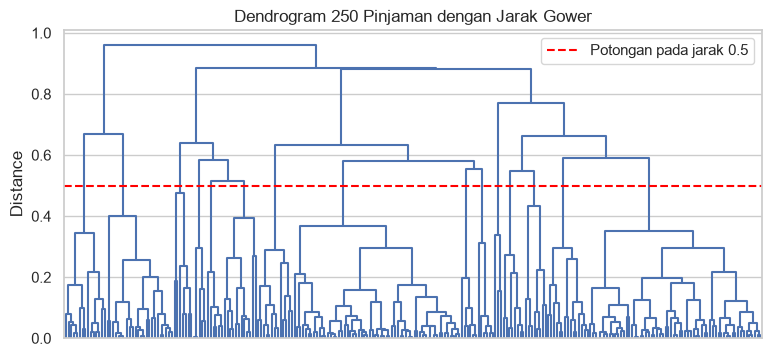

Jumlah cluster pada jarak 0.5: 15
         jumlah      home             purpose  dti_min  dti_max
cluster                                                        
15           62      RENT  debt_consolidation    1.680   31.090
8            60  MORTGAGE  debt_consolidation    3.540   32.630
2            24  MORTGAGE         credit_card    6.260   30.880
1            15      RENT         credit_card    7.610   32.300
14           15      RENT               other    2.850   28.060
7            13  MORTGAGE    home_improvement    2.010   30.640


In [29]:
rng = np.random.default_rng(301)

sample_loans = loan_data[numeric_columns + categorical_columns].iloc[
    rng.choice(len(loan_data), size=250, replace=False)
]

gower_sample = gower_distance(sample_loans, numeric_columns, categorical_columns)
linkage_gower = linkage(squareform(gower_sample, checks=False), method="complete")

sample_loans = sample_loans.assign(cluster=fcluster(linkage_gower, 0.5, criterion="distance"))

fig, ax = plt.subplots(figsize=(9, 4))

dendrogram(linkage_gower, no_labels=True, color_threshold=0, ax=ax)
ax.axhline(0.5, color="red", linestyle="--", label="Potongan pada jarak 0.5")

ax.set_ylabel("Distance")
ax.set_title("Dendrogram 250 Pinjaman dengan Jarak Gower")
ax.legend()

plt.show()

summary = sample_loans.groupby("cluster").agg(
    jumlah=("dti", "size"),
    home=("home_", lambda values: ", ".join(sorted(values.unique()))),
    purpose=("purpose_", lambda values: ", ".join(sorted(values.unique()))),
    dti_min=("dti", "min"),
    dti_max=("dti", "max"),
).sort_values("jumlah", ascending=False)

print(f"Jumlah cluster pada jarak 0.5: {len(summary)}")
print(summary.head(6))

### Interpretasi

Jarak Gower berkisar antara 0 dan 1. Pada lima pinjaman pertama, jarak
terbesar adalah antara pinjaman 1 dan 2 (0.814): keduanya berbeda `home_`
(OWN dan RENT) dan `purpose_` (small_business dan other), serta `dti`
dan `payment_inc_ratio` yang cukup berbeda. Jarak terkecil adalah antara
pinjaman 2 dan 4 (0.309): keduanya RENT dengan tujuan yang sama (other)
sehingga jaraknya hanya berasal dari selisih numerik. Setiap variabel
berkontribusi setara pada jarak Gower, sehingga satu ketidakcocokan
kategori menambah 0.25 pada jarak (karena dirata-ratakan dari empat
variabel).

Hierarchical clustering pada 250 pinjaman acak dengan jarak Gower,
dipotong pada jarak 0.5, menghasilkan 15 cluster. Cluster terbesar
berisi kombinasi kategori yang seragam: 62 pinjaman semuanya RENT dengan
debt_consolidation, 60 pinjaman semuanya MORTGAGE dengan
debt_consolidation, dan 24 pinjaman semuanya MORTGAGE dengan credit_card.
Pinjaman dengan kategori berbeda terpisah sebesar 0.25 untuk setiap
variabel kategorikal yang berbeda, sehingga baru dapat tergabung bila
selisih numeriknya kecil. Di dalam setiap cluster, `dti` tetap bervariasi
lebar (misalnya 1.68 sampai 31.09 pada cluster terbesar). Jarak Gower
dengan demikian memberi bobot yang setara pada variabel numerik dan
kategorikal, berbeda dengan K-means pada data dummy yang dibahas
berikut.

### Masalah Clustering pada Data Campuran

Alternatif lain adalah mengubah variabel kategorikal menjadi variabel dummy lalu memakai K-means. Pendekatan ini bermasalah: setelah standardisasi, variabel dummy bernilai 0 atau 1 memiliki pengaruh yang besar pada jarak sehingga dapat mengalahkan variabel numerik. Contohnya, K-means dengan K = 4 pada pinjaman `default` dengan `dti`, `payment_inc_ratio`, `home_`, dan `pub_rec_zero`.

In [30]:
mixed_columns = ["dti", "payment_inc_ratio", "home_", "pub_rec_zero"]

dummies = pd.get_dummies(defaults[mixed_columns], prefix={"home_": "home"}, dtype=int)

mixed_scaler = StandardScaler()
mixed_scaled = mixed_scaler.fit_transform(dummies * 1.0)

kmeans_mixed = KMeans(n_clusters=4, n_init=10, random_state=1).fit(mixed_scaled)

order = np.argsort(-np.bincount(kmeans_mixed.labels_))
centers_mixed = pd.DataFrame(
    mixed_scaler.inverse_transform(kmeans_mixed.cluster_centers_)[order],
    columns=dummies.columns
).round(3) + 0.0
centers_mixed["size"] = np.bincount(kmeans_mixed.labels_)[order]

print("Rata-rata setiap variabel pada seluruh pinjaman default:")
print(dummies.mean().round(3).to_string())

print("\nPusat cluster (skala asli):")
print(centers_mixed.to_string())

Rata-rata setiap variabel pada seluruh pinjaman default:
dti                 17.152
payment_inc_ratio    8.770
pub_rec_zero         0.914
home_MORTGAGE        0.431
home_OWN             0.083
home_RENT            0.485

Pusat cluster (skala asli):
     dti  payment_inc_ratio  pub_rec_zero  home_MORTGAGE  home_OWN  home_RENT   size
0 16.992              9.105         1.000          0.000     0.000      1.000  10138
1 17.456              8.423         1.000          1.000     0.000      0.000   8857
2 17.198              9.267         0.918          0.000     1.000      0.000   1888
3 16.505              8.064         0.000          0.516     0.000      0.484   1788


### Interpretasi

Setelah variabel kategorikal diubah menjadi dummy dan distandardisasi,
cluster K-means hampir seluruhnya ditentukan oleh variabel dummy.
Cluster terbesar (10,138 pinjaman) adalah pinjaman RENT dengan
`pub_rec_zero` = 1, yang kedua (8,857) MORTGAGE dengan `pub_rec_zero` =
1, yang ketiga (1,888) OWN, dan yang keempat (1,788) seluruhnya memiliki
`pub_rec_zero` = 0 (campuran MORTGAGE dan RENT). Sebaliknya, `dti` (16.5
sampai 17.5) dan `payment_inc_ratio` (8.1 sampai 9.3) hampir sama di
semua cluster, padahal keduanya variabel numerik yang paling informatif.

Penyebabnya, variabel dummy hanya bernilai 0 atau 1 dan setelah
standardisasi selisih antara kedua nilai itu besar. Misalnya `home_OWN`
hanya dimiliki 8.3% pinjaman, sehingga perpindahan dari 0 ke 1 setara
sekitar 3.6 simpangan baku dan mengalahkan selisih numerik yang lebih
halus. Akibatnya cluster hanya mencerminkan kombinasi kategori. Karena
itu jarak Gower, yang menormalkan setiap variabel ke rentang 0 sampai 1,
lebih sesuai untuk data campuran.

## 8. Ringkasan Chapter 7

Beberapa teknik utama pada unsupervised learning adalah:

| Teknik | Fungsi |
|---|---|
| PCA | Meringkas variabel yang berkorelasi menjadi beberapa component yang menjelaskan variance terbesar |
| Scree Plot | Menentukan jumlah component yang dipertahankan |
| Loading | Menunjukkan bobot setiap variabel pada sebuah component |
| Correspondence Analysis | Memetakan baris dan kolom tabel kontingensi ke ruang berdimensi rendah |
| K-Means | Membagi data menjadi K cluster berdasarkan jarak ke pusat cluster |
| Elbow Method | Membantu memilih jumlah cluster dari penurunan inertia |
| Hierarchical Clustering | Membentuk cluster bertingkat yang digambarkan sebagai dendrogram |
| Linkage | Menentukan cara mengukur ketidakmiripan antarcluster |
| Mixture of Normals (GMM) | Memodelkan cluster sebagai distribusi normal dengan rata-rata dan kovarians sendiri |
| BIC | Memilih jumlah komponen dan jenis kovarians |
| Standardisasi | Menyamakan skala variabel sebelum PCA atau K-means |
| Jarak Gower | Mengukur jarak pada data campuran numerik dan kategorikal |

## 9. Kesimpulan

Unsupervised learning menemukan struktur pada data tanpa variabel
target. PCA meringkas variabel yang berkorelasi: pada 16 saham, lima
component pertama menjelaskan 80.9% variance dan component pertama
mewakili gerakan pasar secara keseluruhan. Correspondence analysis
memetakan tabel kontingensi sehingga hubungan antara tugas rumah tangga
dan pelaksananya terlihat pada dua dimensi.

K-means, hierarchical clustering, dan model-based clustering
mengelompokkan data dengan cara berbeda. K-means cepat tetapi
memerlukan jumlah cluster di awal dan cenderung membentuk kelompok bulat;
elbow method pada data saham tidak menunjukkan siku yang jelas.
Hierarchical clustering tidak memerlukan jumlah cluster di awal, tetapi
hasilnya sangat bergantung pada linkage: single linkage membentuk satu
cluster raksasa (1,127 dari 1,131 hari), sedangkan Ward menghasilkan
cluster yang seimbang. Model-based clustering memodelkan sebaran setiap
cluster; pada data XOM dan CVX, BIC memilih dua komponen yang dibedakan
oleh volatilitas (hari tenang dan hari bergejolak), bukan oleh arah
gerakan.

Hasil PCA dan clustering sangat dipengaruhi skala variabel. Tanpa
standardisasi, PCA didominasi GOOGL dan AMZN, dan K-means pada data
pinjaman hanya mengikuti pendapatan dan saldo revolving. Untuk data
kategorikal atau campuran, variabel dummy yang distandardisasi dapat
mendominasi jarak sehingga jarak Gower lebih sesuai.

Karena unsupervised learning tidak memiliki jawaban benar yang dapat
diperiksa, hasilnya perlu dinilai dari kemudahan tafsir, stabilitas
terhadap pilihan metode dan parameter, serta kegunaannya bagi tujuan
analisis.

## Referensi

Bruce, P., Bruce, A., & Gedeck, P. (2020).
*Practical Statistics for Data Scientists: 50+ Essential Concepts
Using R and Python*. 2nd Edition. O'Reilly Media.

Repository kode dan dataset:
https://github.com/gedeck/practical-statistics-for-data-scientists